# Module 7 — Pretrained Models and the Hugging Face Ecosystem

## Lesson 7.1 — Understanding Pretrained Models


In Module 6 you built a Transformer from its parts and trained it to write text. It worked, but it was small, it learned from Shakespeare one character at a time, and its output showed it. Training a Transformer well takes enormous amounts of text and computing power, far more than a laptop and an afternoon.

That raises a practical question every AI engineer faces: if training a good model is so expensive, how does anyone build language or vision features without a research lab's budget? The answer is that most of them never train the big model at all. Someone else trains it once on a huge, general collection of data and publishes the result. Everyone else downloads it and puts it to work. A model like that is called a **pretrained model**, and Module 7 is about using them well.

This first note looks at pretrained models as a whole: what one is, where it comes from, what it actually learned, and what you are getting when you download one. The later notes in this module show you where to find these models (7.2 and 7.3), how to load and run them (7.4), how to build features with them (7.5), what they cost to run (7.6), and how to choose one for a real task (7.7).

**Key question:** *How can AI engineers leverage models that have already learned useful representations?*

### Learning objectives
- explain what a pretrained model is, and show by measurement that its value lives in its weights rather than its code;
- describe the lifecycle from data to pretraining to downstream use, and the difference between a base model and an adapted one;
- probe what a language model learned during pretraining, and say where that knowledge is reliable and where it is not;
- compare a pretrained model with training from scratch and with traditional machine learning, and explain when each wins;
- read a model's configuration, count its parameters by component, and connect parameter count to file size;
- explain what a checkpoint and a model version are, and load a pinned version.

### Prerequisites

 this note builds on the encoder-and-head picture from Note 5.1, on tokens, embeddings and the static-versus-contextual distinction from Note 5.3, and on the Transformer from Module 6, especially the idea from Note 6.2 that a model and its tokeniser are a pair. You should be comfortable with logistic regression in scikit-learn and the sign test from Module 5.

### Setup

Run the cell below first. It imports the libraries for this note, fixes the random seeds to reduce variation within a controlled environment, and checks for a GPU. Everything in this note runs on a CPU.

You will see some warnings while this notebook runs, and they are harmless:
- a **TqdmWarning** saying "IProgress not found" (progress bars fall back to plain text);
- on a Mac, a few lines starting with `W` about "Redirects" and `register_constant()`, printed when the libraries load;
- "Loading weights" progress bars, and a message that you are "sending unauthenticated requests to the HF Hub". You don't need an account or a token for anything in this module.

We will meet one more kind of message, a **LOAD REPORT**, in Section 4, where it is part of the lesson.

**Environment and reference results.** Use Python 3.12 and [requirements.txt](../static/notebook-support/module78/requirements.txt) (also supplied at the root of the Module 7/8 notebook bundle). Install packages into a separate environment, restart the kernel, and run from the beginning. The saved outputs are the author's CPU reference run, with approved explanatory corrections. Seeds and artifact revisions reduce variation; numbers and timings can differ across hardware. No account or paid API is required for the public teaching models. Initial model/data downloads require internet access.

In [1]:
import os, re, gc, hashlib
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers
from datasets import load_dataset
from huggingface_hub import hf_hub_download, HfApi
from transformers import (pipeline, AutoConfig, AutoTokenizer, AutoModel,
                          AutoModelForMaskedLM, AutoModelForSequenceClassification)

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| Transformers", transformers.__version__, "| device:", device)

# Freeze the public artifacts used by the recorded experiments.
MODEL_REVISIONS = {'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'distilbert/distilbert-base-uncased-finetuned-sst-2-english': '714eb0fa89d2f80546fda750413ed43d93601a13', 'sentence-transformers/all-MiniLM-L6-v2': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41', 'HuggingFaceTB/SmolLM2-135M': '93efa2f097d58c2a74874c7e644dbc9b0cee75a2', 'distilbert/distilgpt2': '2290a62682d06624634c1f46a6ad5be0f47f38aa', 'HuggingFaceTB/SmolLM2-135M-Instruct': '12fd25f77366fa6b3b4b768ec3050bf629380bac', 'HuggingFaceTB/SmolLM2-360M-Instruct': 'a10cc1512eabd3dde888204e902eca88bddb4951', 'Qwen/Qwen2.5-0.5B': '060db6499f32faf8b98477b0a26969ef7d8b9987', 'Qwen/Qwen2.5-7B': 'd149729398750b98c0af14eb82c78cfe92750796', 'google-bert/bert-large-uncased': '6da4b6a26a1877e173fca3225479512db81a5e5b', 'distilbert/distilbert-base-uncased': '12040accade4e8a0f71eabdb258fecc2e7e948be', 'google-bert/bert-base-uncased': '86b5e0934494bd15c9632b12f734a8a67f723594', 'cardiffnlp/twitter-roberta-base-sentiment-latest': '3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7', 'distilbert/distilbert-base-cased-distilled-squad': '564e9b582944a57a3e586bbb98fd6f0a4118db7f', 'google/vit-base-patch16-224': '3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3', 'sshleifer/distilbart-cnn-12-6': 'a4f8f3ea906ed274767e9906dbaede7531d660ff', 'textattack/distilbert-base-uncased-imdb': '5b0f46c2fc4b86bf21f0ec0409bed77ee142b332', 'google/gemma-2-2b': 'c5ebcd40d208330abc697524c919956e692655cf', 'meta-llama/Llama-3.2-1B': '4e20de362430cd3b72f300e6b0f18e50e7166e08'}
DATASET_REVISIONS = {'stanfordnlp/imdb': 'e6281661ce1c48d982bc483cf8a173c1bbeb5d31', 'stanfordnlp/sst2': '8d51e7e4887a4caaa95b3fbebbf53c0490b58bbb'}

def benchmark_clock():
    """Read elapsed time after completing any queued CUDA work."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    import time
    return time.perf_counter()

def ordered_fingerprint(texts, labels):
    """Hash ordered text/label pairs so paired predictions cannot be silently misaligned."""
    import json, hashlib
    rows = [[str(t), int(y)] for t, y in zip(texts, labels)]
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(',', ':')).encode()).hexdigest()

/Users/solomonpromise/Documents/Simplilearn Classes/Deep Learning/_work78/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1017 12:42:21.110000 71310 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1017 12:42:21.248000 71310 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1017 12:42:21.268000 71310 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


PyTorch 2.14.1 | Transformers 5.20.1 | device: cpu


## 1. The Big Picture: What Is a Pretrained Model?

### 1.1 A model that works before you train it

Let's start with the whole thing working, then take it apart. The cell below downloads a ready-made sentiment model from the **Hugging Face Hub**, a public website where people share trained models (Note 7.2 tours it properly). The model is called DistilBERT, a compact member of the BERT family of Transformer encoders. The version we load has already been adapted to judge whether a sentence about a film is positive or negative.

The `pipeline` function wraps the whole process, from text in to a label out, in one object. Note the `device=device` argument: without it, the library may pick a device on its own, and your numbers might not match these notes.

In [2]:
BASE = "distilbert/distilbert-base-uncased"                           # a general-purpose pretrained model
SST2 = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"   # the same model, adapted to sentiment

sentiment = pipeline("sentiment-analysis", model=SST2, device=device, revision=MODEL_REVISIONS.get(SST2))   # downloads about 268 MB the first time

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 13899.93it/s]

Now let's give it four short reviews. I wrote these before running the model, so they weren't chosen to make it look good.

In [3]:
reviews = ["A wonderful film with a brilliant cast.",
           "The plot was dull and the acting was even worse.",
           "I would happily watch it again tomorrow.",
           "Two hours of my life I will never get back."]
for review, out in zip(reviews, sentiment(reviews)):
    print(f"{out['label']:<9} {out['score']:.3f}  {review}")

POSITIVE  1.000  A wonderful film with a brilliant cast.
NEGATIVE  1.000  The plot was dull and the acting was even worse.
POSITIVE  1.000  I would happily watch it again tomorrow.
POSITIVE  0.745  Two hours of my life I will never get back.


Three are right, with a confidence score of 1.000. The fourth, "Two hours of my life I will never get back", is a complaint, but the model calls it positive with a score of 0.745. There's no unhappy word in the sentence; the complaint lives in the idiom. Keep this in mind: a working model is not a perfect one, and Note 7.5 tests this model much harder.

We did no training at all. Every weight in that model was set by someone else, on someone else's computer, before we arrived. That is what a pretrained model is: **a model whose weights have already been learned, published so that others can use them without training from the start.**

### 1.2 The data we will use throughout Modules 7 and 8

Four sentences prove nothing, so we need a proper test. We'll use the **IMDb** movie-review dataset: reviews from the Internet Movie Database, each labelled positive or negative, with an official training half and test half. The same split will be used in every note of Modules 7 and 8, so that results from different notes can be compared fairly.

The function below builds that split. It does three things, for reasons you met in Module 4:
- **It removes duplicate reviews before splitting.** If a review appears twice, one copy could land in training and the other in evaluation, and the model would be tested on something it has already seen.
- **It also removes test reviews that appear in the training half.** That's the same leak, across the official split.
- **It carves a validation set out of the training half,** with a fixed seed. Settings are chosen on validation and reported once on test.

It also cleans one quirk: the reviews contain HTML line-break tags (`<br />`), which we replace with spaces. Finally, `fingerprint` turns a set of texts into a short code. If two notebooks print the same fingerprint, they are using exactly the same reviews. That gets checked rather than assumed.

In [4]:
def load_imdb_split(seed=0, n_val=2500, n_eval=1000, verbose=True):
    """The fixed IMDb split shared by every note in Modules 7 and 8."""
    ds = load_dataset("stanfordnlp/imdb", cache_dir="data/imdb",
                      data_files={"train": "plain_text/train-*.parquet",
                                  "test":  "plain_text/test-*.parquet"}, revision=DATASET_REVISIONS.get("stanfordnlp/imdb"))
    def dedup(texts, labels, seen):
        keep = []
        for i, t in enumerate(texts):
            if t not in seen:                              # keep only the first copy of each review
                seen.add(t); keep.append(i)
        return [texts[i] for i in keep], np.array([labels[i] for i in keep])
    tr_x, tr_y = dedup(list(ds["train"]["text"]), list(ds["train"]["label"]), set())
    te_x, te_y = dedup(list(ds["test"]["text"]), list(ds["test"]["label"]), set(tr_x))  # also drops test reviews already in train
    if verbose:
        print(f"official split: {len(ds['train'])} train, {len(ds['test'])} test reviews")
        print(f"duplicates removed: {len(ds['train']) - len(tr_x)} from train, "
              f"{len(ds['test']) - len(te_x)} from test (repeats, or reviews that are also in train)")
    clean = lambda xs: [x.replace("<br />", " ") for x in xs]                         # remove HTML line breaks
    rng = np.random.default_rng(seed)
    p = rng.permutation(len(tr_x)); v, t = p[:n_val], p[n_val:]                       # validation is carved from train
    q = rng.permutation(len(te_x))[:n_eval]                                           # a fixed sample of the test set
    split = {"train": (clean([tr_x[i] for i in t]), tr_y[t]),
             "val":   (clean([tr_x[i] for i in v]), tr_y[v]),
             "test":  (clean(te_x), te_y)}
    split["val_eval"] = (split["val"][0][:n_eval], split["val"][1][:n_eval])
    split["test_eval"] = (clean([te_x[i] for i in q]), te_y[q])
    return split

def fingerprint(texts):
    """A short ID for a set of texts: identical sets give identical fingerprints."""
    return hashlib.sha256("\n".join(sorted(texts)).encode()).hexdigest()[:12]

The first run downloads the dataset into a `data/imdb` folder next to this notebook. You'll see "Generating train split" progress lines.

In [5]:
imdb = load_imdb_split()
for name, (x, y) in imdb.items():
    print(f"{name:<9} {len(x):>6} reviews | positive share {y.mean():.3f} | fingerprint {fingerprint(x)}")

official split: 25000 train, 25000 test reviews
duplicates removed: 96 from train, 322 from test (repeats, or reviews that are also in train)
train      22404 reviews | positive share 0.502 | fingerprint fb3a1229f951
val         2500 reviews | positive share 0.492 | fingerprint 07758bc36c9b
test       24678 reviews | positive share 0.503 | fingerprint 429c5557b6d4
val_eval    1000 reviews | positive share 0.495 | fingerprint 9934ffeaac91
test_eval   1000 reviews | positive share 0.515 | fingerprint fc9fa98701bc


Each official half has 25,000 reviews, and both contained duplicates: 96 were removed from train and 322 from test. That leaves 22,404 reviews for training, 2,500 for validation and 24,678 for testing, all close to half positive. Running a Transformer over 24,678 reviews on a CPU takes a long time, so most evaluations in these notes use two fixed samples of 1,000 reviews: `val_eval` (the first 1,000 validation reviews) and `test_eval` (a seeded sample of the test set). Their fingerprints will appear again in later notes.

> **Common mistake:** trusting an official split to be clean. IMDb's halves share some reviews, so a model trained on one half has seen part of the other. Always deduplicate *before* splitting, and check across any split you are given.

### 1.3 Same architecture, no pretraining

Here is the experiment that shows where the value lies. We'll score the pretrained model on the first 500 validation reviews. Then we build a model with the **identical architecture**, the same layers and the same number of weights, but with random weights, and score it on the same 500 reviews.

The pipeline cuts each review to its first 256 tokens (`max_length=256`). As you saw in Note 6.2, a Transformer can only look at a limited number of tokens at once, and many reviews are longer than that. Note 7.4 explains truncation in detail.

In [6]:
eval_x, eval_y = imdb["val_eval"][0][:500], imdb["val_eval"][1][:500]   # the first 500 validation reviews

def pipeline_predict(clf, texts):
    out = clf(texts, truncation=True, max_length=256, batch_size=32)      # long reviews are cut to 256 tokens
    return np.array([int(o["label"] == "POSITIVE") for o in out])         # 1 = positive, 0 = negative

pred_pretrained = pipeline_predict(sentiment, eval_x)
acc_pretrained = (pred_pretrained == eval_y).mean()
print(f"pretrained + adapted weights: accuracy {acc_pretrained:.3f} | predicts positive for {pred_pretrained.mean():.1%} of reviews")

pretrained + adapted weights: accuracy 0.874 | predicts positive for 48.0% of reviews


To build the untrained twin, we load only the model's **configuration**, the description of its architecture without any weights (Section 6 looks inside one), and ask the library to build a fresh model from it.

In [7]:
config = AutoConfig.from_pretrained(SST2, revision=MODEL_REVISIONS.get(SST2))                       # the architecture's description, no weights
tokenizer = AutoTokenizer.from_pretrained(SST2, revision=MODEL_REVISIONS.get(SST2))
torch.manual_seed(0)
random_model = AutoModelForSequenceClassification.from_config(config)   # same architecture, random weights
random_clf = pipeline("sentiment-analysis", model=random_model, tokenizer=tokenizer, device=device)
pred_random = pipeline_predict(random_clf, eval_x)
print(f"same architecture, random weights: accuracy {(pred_random == eval_y).mean():.3f} | predicts positive for {pred_random.mean():.1%} of reviews")
print(f"share of the larger class in these 500 reviews: {max(eval_y.mean(), 1 - eval_y.mean()):.3f}")
del random_clf, random_model; _ = gc.collect()

same architecture, random weights: accuracy 0.486 | predicts positive for 8.4% of reviews
share of the larger class in these 500 reviews: 0.510


The difference is stark. The pretrained model scores 0.874 on 500 reviews held out from our own training. Its untrained twin scores 0.486, which is chance: it calls almost every review negative (only 8.4% positive) and is right only when the review happens to be negative. Nothing about the code differs. Same architecture, same tokeniser, same pipeline. **With architecture and tokeniser held fixed, the trained weights make the difference in this experiment.**

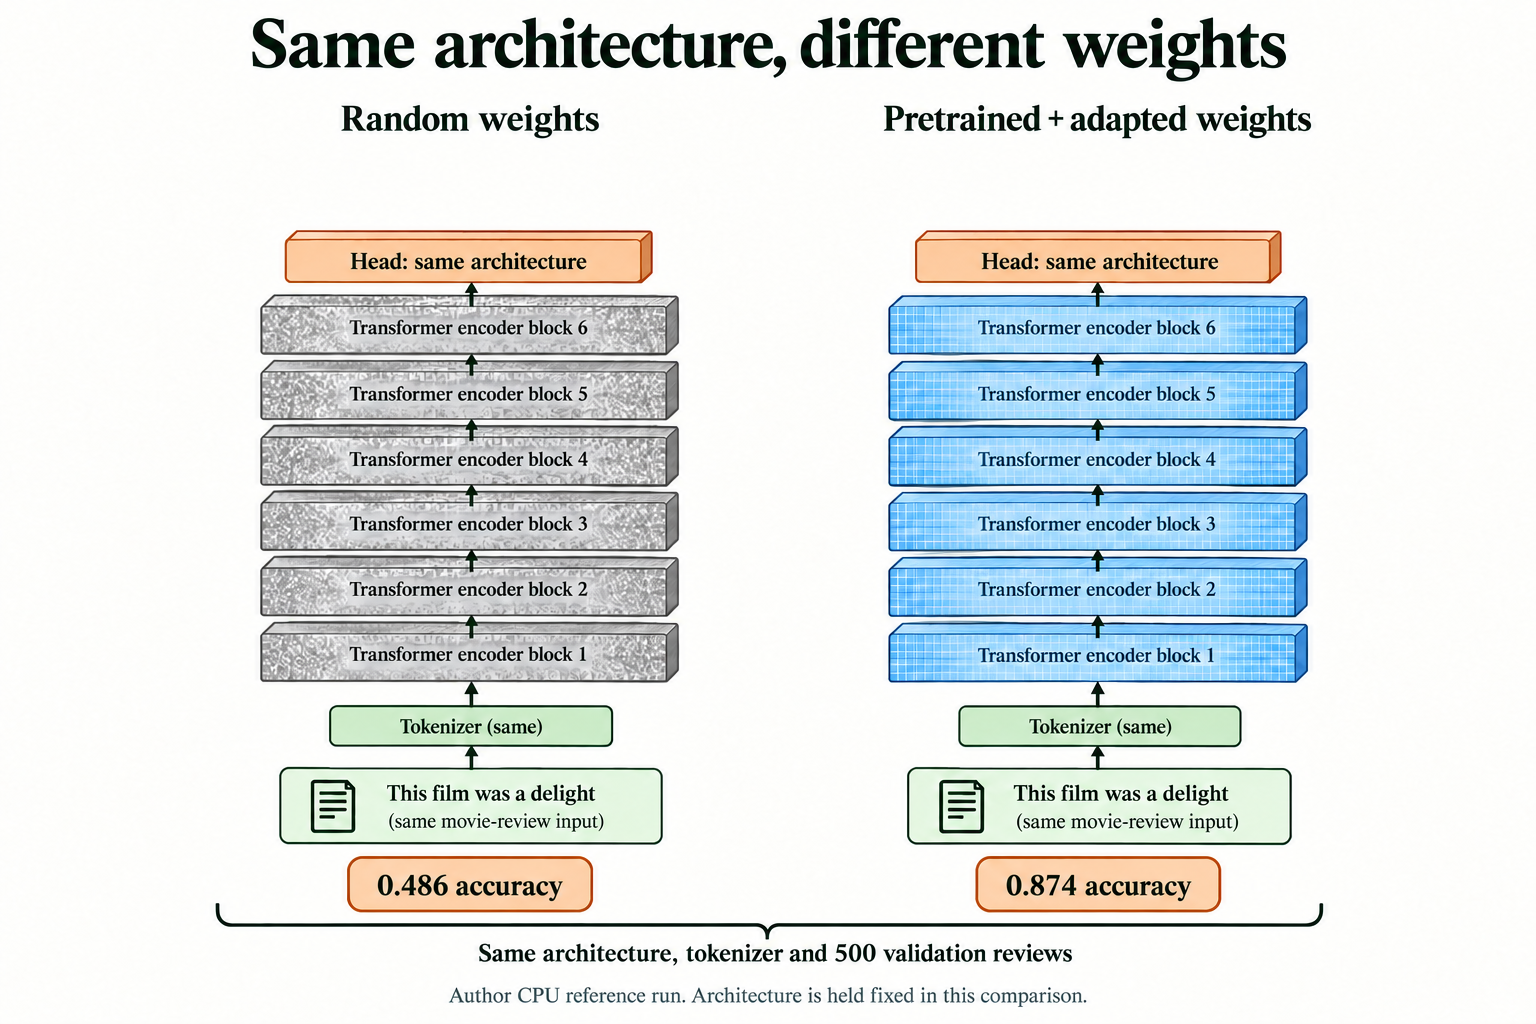

*Figure 7.1.1. The architecture and tokenizer are held fixed. The saved CPU run scores 0.486 with random weights and 0.874 with pretrained/adapted weights on the same 500 validation reviews; this does not audit all upstream exposure.*

> **Key terms**
> - **Pretrained model:** a model whose weights were learned by someone else, usually on a very large dataset, and published for others to use or adapt.
> - **Weights (parameters):** the learned numbers inside a model. Training means adjusting them.
> - **Architecture:** the structure of a model, meaning which layers it has, their sizes and how they connect. Two models can share an architecture and behave completely differently.
> - **Configuration:** a small file that describes an architecture in words and numbers, so the library can rebuild it.
> - **Pipeline:** a Hugging Face helper that bundles tokenising, running the model and turning its output into a readable answer.

**Check yourself.**

1. The random-weights model scored 0.486, close to half, even though it knows nothing. Why isn't its accuracy close to zero?

<details>
<summary>Worked answer</summary>

Because the reviews are balanced. The random model called almost every review negative (only 8.4% positive), and about half the reviews really are negative, so it is right on those almost by default. A model that knows nothing about sentiment lands near the share of the class it guesses, not near zero. That's why chance, not zero, is the baseline to beat.

</details>

The next section steps back to ask where a model like this comes from.

> **Interpret the evidence carefully.** The comparison fixes architecture, preprocessing and tokeniser; it isolates the benefit of trained weights in that setup. These reviews are held out from our own training. Upstream documentation is evidence about earlier training data, not an exhaustive proof that a public checkpoint never encountered related material.

## 2. The Lifecycle: Data → Pretraining → Downstream Use

The sentiment model we loaded did not begin life as a sentiment model. Its story has two stages, and almost every pretrained model you'll meet follows the same pattern.

**Stage one: pretraining.** A large model is trained on a huge collection of general data, such as books and web pages for text. Nobody labels this data. Instead, the model is given a task that the data can grade by itself. In Note 6.6 your Transformer predicted the *next* character. DistilBERT was pretrained on a close cousin of that task, **masked language modelling**: words in a sentence are hidden behind a `[MASK]` token, and the model must guess them from the words on *both* sides. Guessing hidden words well, across billions of sentences, forces a model to learn a lot about how language works. The result of this stage is a **base model**: general-purpose, but not yet built for any particular job.

**Stage two: downstream use.** A **downstream task** is the job you actually care about, such as sentiment, spam detection or question answering. "Downstream" because it comes after pretraining. The base model is adapted to it, usually by adding a small new output layer and training a little more on labelled examples. That extra training is called **fine-tuning**. Our sentiment model is DistilBERT fine-tuned on **SST-2**, a dataset of short sentences from film reviews labelled positive or negative.

We can watch the base model do its own pretraining task. The `fill-mask` pipeline hides nothing itself; we write `[MASK]` where we want a guess.

In [8]:
fill = pipeline("fill-mask", model=BASE, device=device, revision=MODEL_REVISIONS.get(BASE))    # the base model doing its own pretraining task
for p in fill("The movie was absolutely [MASK].", top_k=5):
    print(f"{p['score']:.3f}  {p['token_str']}")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 7698.53it/s]

0.110  fantastic
0.069  fabulous
0.050  successful
0.031  perfect
0.026  spectacular


All five guesses are positive adjectives that fit the sentence: "fantastic" with probability 0.110, then "fabulous", "successful" and so on. The base model was never told about sentiment, but filling in blanks taught it that "absolutely" before a blank about a movie is usually followed by strong praise.

Now let's compare the two models' parts. In Note 5.1 we split networks into an **encoder** (often called the **body**) that builds a representation, and a **head** that uses it. Hugging Face names the body's weights `distilbert.…`, so we can count them separately.

In [9]:
base_mlm, sst2_model = fill.model, sentiment.model
for name, m in [("base", base_mlm), ("SST-2", sst2_model)]:
    body = sum(p.numel() for n, p in m.named_parameters() if n.startswith("distilbert."))
    head = sum(p.numel() for n, p in m.named_parameters() if not n.startswith("distilbert."))
    print(f"{name:<6} {type(m).__name__:<36} body {body:>11,} | head {head:>9,}")
print("masked-word head reuses the word-embedding table:",
      base_mlm.vocab_projector.weight is base_mlm.distilbert.embeddings.word_embeddings.weight)

base   DistilBertForMaskedLM                body  66,362,880 | head   622,650
SST-2  DistilBertForSequenceClassification  body  66,362,880 | head   592,130
masked-word head reuses the word-embedding table: True


The bodies are exactly the same size, 66,362,880 parameters each. Only the heads differ. The base model's head (622,650 parameters as counted here) turns each position's vector back into a score for every word in the vocabulary. It doesn't need its own copy of the big word table: the last line shows it reuses the body's word-embedding table, a common trick called **weight tying**, so the shared table is counted only once, in the body. The SST-2 head (592,130 parameters) turns the whole text into just two scores.

The output shapes make the difference concrete:

In [10]:
enc = tokenizer("The movie was absolutely [MASK].", return_tensors="pt").to(device)   # 1 text, 9 tokens
with torch.no_grad():
    print("base  output:", tuple(base_mlm(**enc).logits.shape))     # (texts, tokens, vocabulary size)
    print("SST-2 output:", tuple(sst2_model(**enc).logits.shape))   # (texts, classes)

base  output: (1, 8, 30522)
SST-2 output: (1, 2)


For 1 sentence of 8 tokens, the base model returns 30522 scores *at every position*: one per vocabulary word, a guess for what could stand there. The SST-2 model returns 2 numbers for the whole sentence, one per class. Same body, different head, different job.

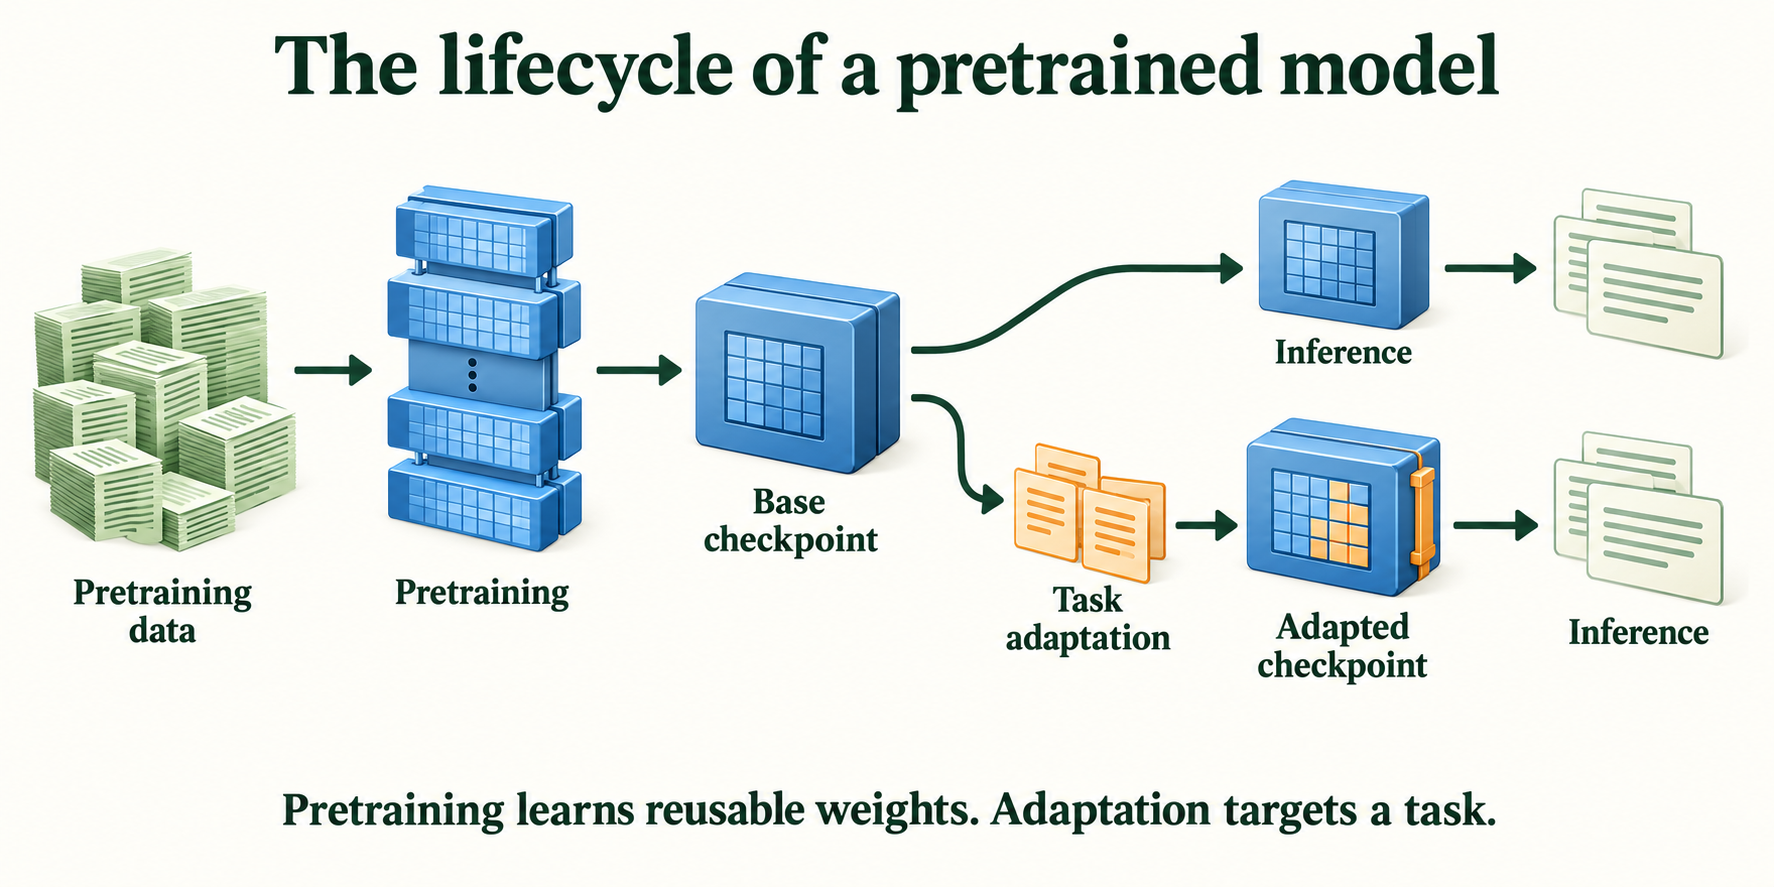

*Figure 7.1.2. Pretraining produces reusable weights. Inference can use a checkpoint directly; optional adaptation changes selected weights for a downstream objective.*

> **Key terms**
> - **Pretraining:** the first, expensive training stage on large, general, usually unlabelled data.
> - **Masked language modelling:** a pretraining task in which some words are hidden and the model must predict them from the surrounding words on both sides.
> - **Base model:** the result of pretraining, before any task-specific adaptation.
> - **Downstream task:** the task you actually want to solve with a pretrained model.
> - **Fine-tuning:** further training of a pretrained model on labelled data for a downstream task.
> - **Body and head:** the body (encoder) builds representations and is shared across tasks; the head is a small task-specific layer on top.

**Check yourself.**

1. The base and SST-2 models have bodies of identical size. Does that mean the bodies contain identical numbers? How could you check? (Section 7 does exactly this.)

<details>
<summary>Worked answer</summary>

No. Identical size only means identical architecture; the numbers inside can differ. To check, load both bodies and compare each tensor with the same name, for example with `torch.equal` or by measuring the size of their difference. Section 7 did this and found that every tensor had changed slightly.

</details>

So pretraining on blanks produced something useful. The next section asks what, exactly, the model picked up.

## 3. What a Model Learns During Pretraining

### 3.1 Probing with blanks

Masked-word guessing is a convenient window into a base model, because we can design blanks that only make sense if the model has learned something specific. Here are four probes. Each tests a different kind of knowledge: grammar, a fact about the world, everyday cause and effect, and who typically does what.

In [11]:
probes = ["She [MASK] to the cinema with her friends yesterday.",
          "The capital of France is [MASK].",
          "The film was so boring that I fell [MASK].",
          "The [MASK] barked at the postman all morning."]
for s in probes:
    top = fill(s, top_k=3)
    print(f"{s:<52} -> " + ", ".join(f"{p['token_str']} ({p['score']:.2f})" for p in top))

She [MASK] to the cinema with her friends yesterday. -> went (0.62), came (0.11), returned (0.06)
The capital of France is [MASK].                     -> marseille (0.14), nantes (0.09), toulouse (0.09)


The film was so boring that I fell [MASK].           -> asleep (0.71), silent (0.06), deaf (0.05)
The [MASK] barked at the postman all morning.        -> dog (0.06), clerk (0.05), sheriff (0.03)


The results are uneven, and that is the lesson.

- **Grammar is strong.** "She [MASK] to the cinema … yesterday" gets "went" with probability 0.62. The model has learned that "yesterday" calls for a past tense and that "to the cinema" calls for a verb of movement.
- **Everyday cause and effect is strong.** "So boring that I fell [MASK]" gets "asleep" at 0.71.
- **Facts are shaky.** "The capital of France is [MASK]" gets "marseille", "nantes" and "toulouse", all French cities, but not the right one, and with low confidence (0.14 for the top guess). The model learned what *kind* of word fits, but not the fact.
- **Typical agents are only partly there.** "The [MASK] barked" does get "dog" first, but with only 0.06, barely ahead of "clerk" and "sheriff".

Pretraining teaches a model the patterns of its training text: grammar, typical word combinations and common associations. It may also absorb facts, but less reliably, and a small model like DistilBERT holds fewer of them. A pretrained language model is not a database. Treat any fact it produces as a guess to check.

### 3.2 Representations that depend on context

The deeper thing pretraining builds is the representation itself. In Note 5.3 we met **static** embeddings, where each word gets one fixed vector, and saw their limit: "bank" gets the same vector whether it is a river bank or a savings bank. A Transformer builds **contextual** representations instead: after each layer, a word's vector has been mixed with information from the words around it.

Let's measure that. We take the base model's body, without any head, and feed it six sentences: three use "bank" in the money sense and three in the river sense. For each sentence we collect the vector for "bank" at the input (layer 0) and after each of the six Transformer layers.

In [12]:
encoder = AutoModel.from_pretrained(BASE, revision=MODEL_REVISIONS.get(BASE)).to(device).eval()      # the pretrained body, without any head
base_tok = AutoTokenizer.from_pretrained(BASE, revision=MODEL_REVISIONS.get(BASE))
money = ["I deposited my salary at the bank.",
         "The bank approved our loan this morning.",
         "She works as a cashier at the bank downtown."]
river = ["We had a picnic on the grassy river bank.",
         "The boat drifted slowly towards the muddy bank.",
         "Fishermen lined the bank of the stream at dawn."]

def bank_vectors(sentence):
    enc = base_tok(sentence, return_tensors="pt").to(device)
    pos = enc.input_ids[0].tolist().index(base_tok.convert_tokens_to_ids("bank"))   # where "bank" sits
    with torch.no_grad():
        states = encoder(**enc, output_hidden_states=True).hidden_states   # 7 x (1, tokens, 768)
    return torch.stack([h[0, pos] for h in states])                        # (7, 768): "bank" after each layer

vecs = {s: bank_vectors(s) for s in money + river}
print(len(vecs), "sentences | vectors per sentence:", tuple(vecs[money[0]].shape))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 8580.12it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


6 sentences | vectors per sentence: (7, 768)


Each sentence gives 7 vectors of 768 numbers each. Now we compare "bank" with "bank" using cosine similarity (Note 5.3): averaged over all pairs that share a meaning, and over all pairs that don't, at every layer.

In [13]:
def mean_cos(group_a, group_b, layer):
    sims = [F.cosine_similarity(vecs[a][layer], vecs[b][layer], dim=0).item()
            for a in group_a for b in group_b if a != b]
    return np.mean(sims)

same = [np.mean([mean_cos(money, money, l), mean_cos(river, river, l)]) for l in range(7)]
diff = [mean_cos(money, river, l) for l in range(7)]
for l in range(7):
    print(f"layer {l}: same meaning {same[l]:.3f} | different meaning {diff[l]:.3f} | gap {same[l]-diff[l]:.3f}")

layer 0: same meaning 0.952 | different meaning 0.961 | gap -0.009
layer 1: same meaning 0.890 | different meaning 0.744 | gap 0.146
layer 2: same meaning 0.845 | different meaning 0.647 | gap 0.198
layer 3: same meaning 0.873 | different meaning 0.675 | gap 0.198
layer 4: same meaning 0.903 | different meaning 0.708 | gap 0.196
layer 5: same meaning 0.926 | different meaning 0.763 | gap 0.163
layer 6: same meaning 0.880 | different meaning 0.642 | gap 0.237


At layer 0 there is no gap at all. The two groups are equally similar (0.952 and 0.961), because at the input "bank" is mostly just its embedding-table entry plus a position, the same as a static embedding. After the first layer the meanings pull apart, and by the last layer the gap is 0.237: money-sense "bank"s average 0.880 with each other, but only 0.642 with river-sense ones. The plot shows the whole picture.

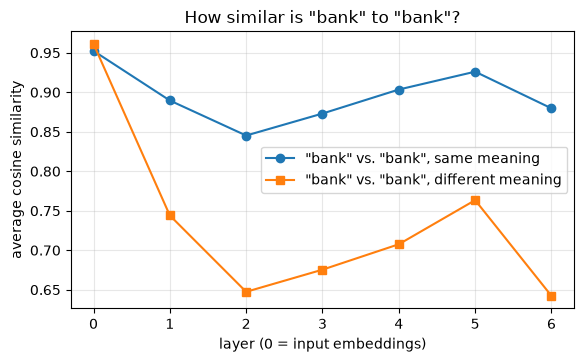

In [14]:
plt.figure(figsize=(6.5, 3.6))
plt.plot(range(7), same, "o-", label='"bank" vs. "bank", same meaning')
plt.plot(range(7), diff, "s-", label='"bank" vs. "bank", different meaning')
plt.xlabel("layer (0 = input embeddings)"); plt.ylabel("average cosine similarity")
plt.title('How similar is "bank" to "bank"?'); plt.legend(); plt.grid(alpha=0.3); plt.show()

Nobody told the model that "bank" has two meanings. It worked that out because guessing hidden words well requires it: the words around "bank" decide what can fill nearby blanks. This is why pretrained representations are so useful downstream. The hard work of turning text into meaningful vectors has already been done.

These are six hand-written sentences, so treat the exact values as an illustration. The pattern of a gap that is absent at the input and opens up inside the network is the general behaviour of contextual models.

> **Key terms**
> - **Probing:** testing what a model has learned by giving it inputs designed to need a specific piece of knowledge.
> - **Contextual representation (contextual embedding):** a vector for a word that depends on the sentence around it; the same word gets different vectors in different contexts.
> - **Hidden states:** the vectors a Transformer produces after each layer; `hidden_states[0]` is the input embedding, and the last is the final output of the body.

> **Common mistake:** asking a pretrained language model for facts and trusting the answer. Its training rewards text that *sounds* right, so a fluent wrong answer, like a French city that isn't the capital, is a normal outcome rather than a rare glitch.

**Check yourself.**

1. At layer 0, "bank" in a river sentence was just as similar to "bank" in a money sentence as two money-sense "bank"s were. Why does the input layer behave like a static embedding?

<details>
<summary>Worked answer</summary>

Layer 0 is the input to the Transformer: each token's vector is its row from the embedding table plus a position vector. No attention has happened yet, so no information from the other words has been mixed in. "Bank" therefore looks almost the same in every sentence, exactly like a static embedding. Context only enters through the attention layers.

</details>

Because these representations are general, one pretrained body can serve many tasks. The next section shows that directly.

## 4. Foundation Models and Their Capabilities

A model pretrained on broad data and then adapted to many different tasks is often called a **foundation model**. The name says what it is for: you build on it. Large language models used in chat assistants, image–text models like CLIP (which you met in Note 5.5 and will use for real in Note 7.5) and the encoder we are using here all play that role, at very different scales.

We can show the idea in miniature. The library has a different model class for each kind of head. Let's load the same base checkpoint four times, each time asking for a different head.

In [15]:
from transformers import AutoModelForQuestionAnswering, AutoModelForTokenClassification
head_classes = {"masked words": AutoModelForMaskedLM,
                "text classification": AutoModelForSequenceClassification,
                "question answering": AutoModelForQuestionAnswering,
                "token labelling": AutoModelForTokenClassification}
models = {task: cls.from_pretrained(BASE, revision=MODEL_REVISIONS.get(BASE)) for task, cls in head_classes.items()}   # one pretrained body, four heads

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 12059.20it/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 13020.94it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 15367.69it/s]


[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
qa_outputs.bias         | MISSING    | 
qa_outputs.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 12192.04it/s]


[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


The library printed a **LOAD REPORT** for each model. This is not an error, and you will see these tables often, so it's worth reading one carefully:
- **UNEXPECTED** lists weights that are in the downloaded file but not needed by the model you asked for. Here they are the masked-word head (`vocab_transform`, `vocab_projector` and so on), which none of the other three tasks use, so they are skipped.
- **MISSING** lists weights the model needs but the file doesn't contain. Here they are the new heads (`classifier`, `qa_outputs`). The library creates them with random values, and the note tells you to train them on your task.

Now let's check what the four models have in common:

In [16]:
ref = models["masked words"].distilbert.transformer.layer[0].attention.q_lin.weight
for task, m in models.items():
    same_body = torch.equal(m.distilbert.transformer.layer[0].attention.q_lin.weight, ref)
    head = sorted({n.rsplit(".", 1)[0] for n, _ in m.named_parameters() if not n.startswith("distilbert.")})
    print(f"{task:<20} same pretrained body: {same_body} | head: {head}")
del models; _ = gc.collect()

masked words         same pretrained body: True | head: ['vocab_layer_norm', 'vocab_projector', 'vocab_transform']
text classification  same pretrained body: True | head: ['classifier', 'pre_classifier']
question answering   same pretrained body: True | head: ['qa_outputs']
token labelling      same pretrained body: True | head: ['classifier']


All four start from the same pretrained body, down to the last number (we compared one weight matrix exactly with `torch.equal`). Only the small heads differ: the masked-word head we've already met, a two-layer `pre_classifier` + `classifier` for whole-text classification, a `qa_outputs` layer that marks where an answer starts and ends in a passage, and a `classifier` that labels each token separately (for example, as a person's name, a place, or neither).

The heads on three of them are random, so those models can't do their tasks yet. That's the point: the expensive part, the body, is shared, and only a small head has to be trained for each new task. Module 8 does that training.

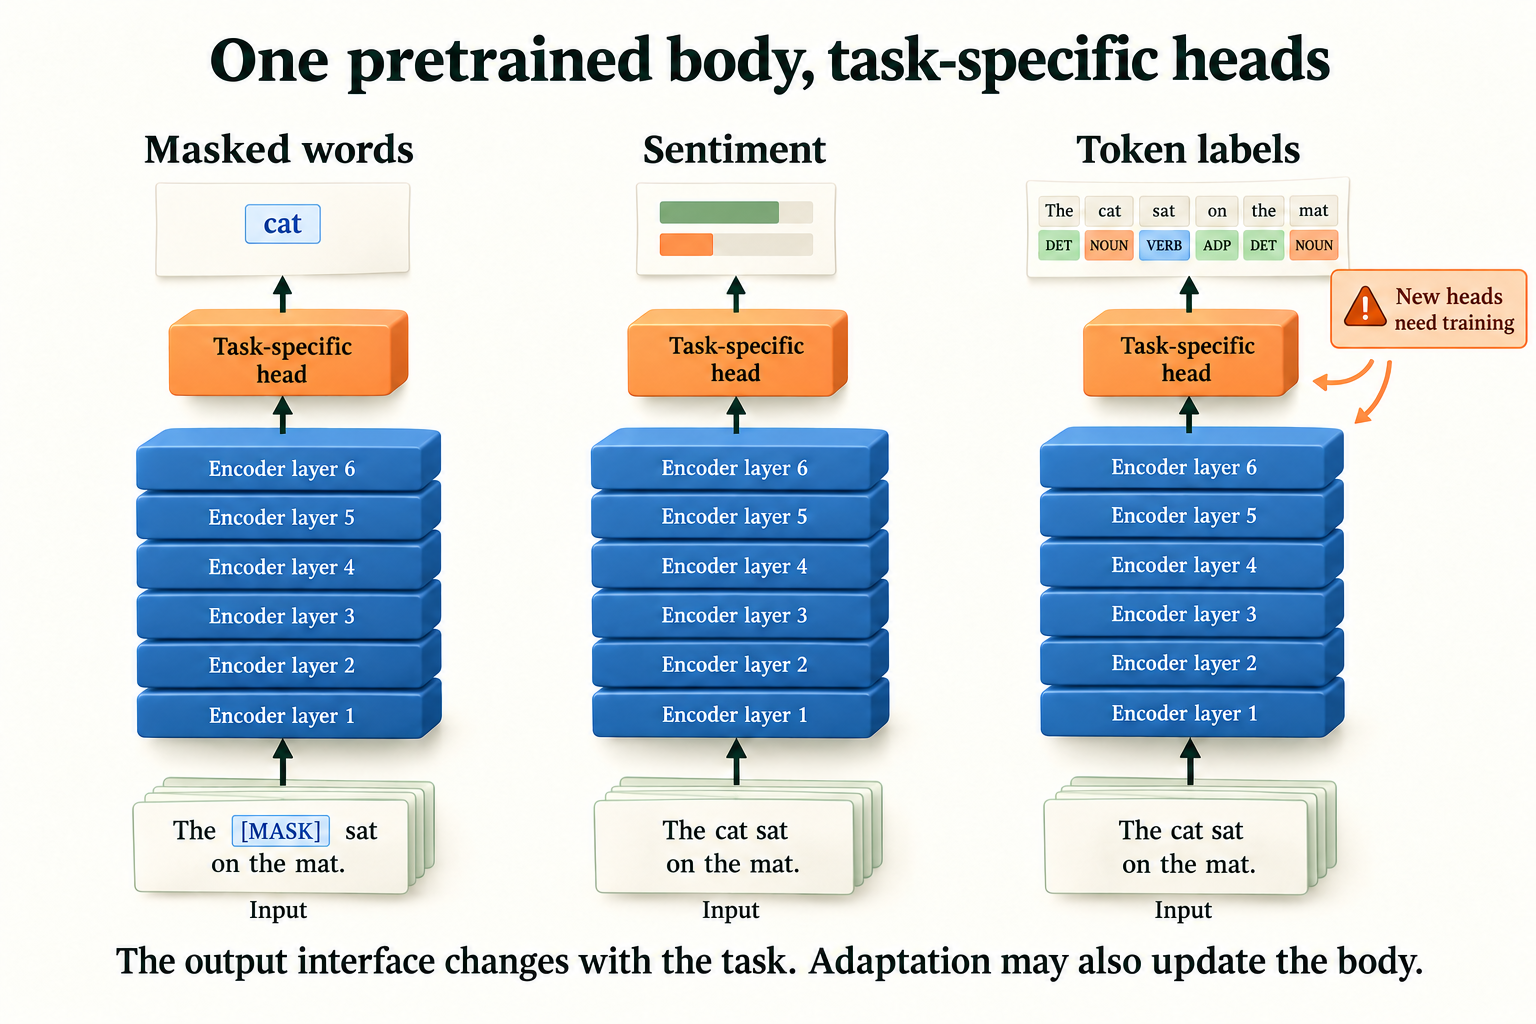

*Figure 7.1.3. A pretrained body can support different output interfaces. Newly initialised heads require training, and task adaptation can update the body as well as the head.*

> **Key terms**
> - **Foundation model:** a model pretrained on broad data and designed to be adapted to many downstream tasks.
> - **Transfer learning:** reusing what a model learned on one task or dataset to help with another.
> - **LOAD REPORT:** the table Hugging Face prints when a checkpoint's weights don't exactly match the model class requested. UNEXPECTED weights are skipped; MISSING weights are created at random.

**Check yourself.**

1. You load a base model with `AutoModelForTokenClassification` and the LOAD REPORT lists `classifier.weight` as MISSING. If you ran this model on a sentence right away, what would its labels be like, and why?

<details>
<summary>Worked answer</summary>

Essentially random. The MISSING note means the `classifier` layer was created with random weights, so even though the body produces good contextual vectors, the head turns them into labels by an untrained rule. The model must be fine-tuned on labelled examples of the tagging task before its labels mean anything.

</details>

A shared body is the promise. The next section tests how much it is actually worth, by comparing it with the alternatives.

## 5. Pretraining vs. Training from Scratch vs. Traditional ML

Suppose you need a sentiment classifier for film reviews. You have three broad options:
- **Traditional machine learning:** turn each review into word counts and fit a linear model. The classic version is **TF-IDF + logistic regression**. TF-IDF scores each word by how often it appears in a review, down-weighted if it appears in almost every review (like "the").
- **Training a neural network from scratch:** start from random weights and learn everything from your own labelled data. We'll use the small bag-of-embeddings network from Note 5.3. A full Transformer trained from scratch would need far more data and computing than we have.
- **Using a pretrained model:** here, the SST-2 model off the shelf, with no IMDb training at all.

The fair way to compare them is to vary how many labelled IMDb reviews the first two get: 100, 1,000, or all 22,404. Small samples are noisy, so for 100 and 1,000 we repeat each experiment on five different random draws of training reviews and report the spread. Everything is scored on the same 500 validation reviews as in Section 1.

One more detail keeps the comparison honest. The neural network needs a setting chosen: how many epochs to train. We choose it on a *different* slice of validation (reviews 1,000 to 2,000), never on the 500 we report.

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
train_x, train_y = imdb["train"]
select_x, select_y = imdb["val"][0][1000:2000], imdb["val"][1][1000:2000]   # for choosing settings; never reported

def tfidf_predict(idx):
    vec = TfidfVectorizer(min_df=2)                                  # one column per word seen at least twice
    X = vec.fit_transform([train_x[i] for i in idx])                 # (n reviews, vocabulary) sparse matrix
    clf = LogisticRegression(max_iter=1000).fit(X, train_y[idx])
    return clf.predict(vec.transform(eval_x))                       # predictions for the 500 reviews

The small network is the one from Note 5.3, redefined here so this notebook stands alone. Its vocabulary is built only from the reviews it is given.

In [18]:
class BagOfEmbeddings(nn.Module):                     # built in Note 5.3
    def __init__(self, vocab_size, dim=32):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, dim, padding_idx=0)
        self.out = nn.Linear(dim, 1)
    def forward(self, x):                             # x: (B, T) token ids
        e = self.emb(x)                               # (B, T, D)
        mask = (x != 0).unsqueeze(-1).float()         # (B, T, 1): 1 for real tokens, 0 for padding
        return self.out((e * mask).sum(1) / mask.sum(1).clamp(min=1)).squeeze(-1)   # (B,)

def scratch_predict(idx, max_epochs=10, max_len=256):
    words = lambda t: re.findall(r"[a-z']+", t.lower())
    counts = Counter(w for i in idx for w in words(train_x[i]))
    stoi = {w: k + 2 for k, w in enumerate(w for w, c in counts.items() if c >= 2)}   # 0 = padding, 1 = unknown
    def to_tensor(texts):
        X = torch.zeros(len(texts), max_len, dtype=torch.long)
        for r, t in enumerate(texts):
            ids = [stoi.get(w, 1) for w in words(t)][:max_len]
            X[r, :len(ids)] = torch.tensor(ids, dtype=torch.long)
        return X
    Xtr, ytr = to_tensor([train_x[i] for i in idx]), torch.tensor(train_y[idx], dtype=torch.float32)
    Xsel, Xev = to_tensor(select_x), to_tensor(eval_x)
    torch.manual_seed(0)
    model = BagOfEmbeddings(len(stoi) + 2)
    opt = torch.optim.Adam(model.parameters(), lr=5e-3)
    best_sel, best_state = -1, None
    for epoch in range(max_epochs):
        for b in torch.randperm(len(Xtr)).split(64):
            opt.zero_grad(); F.binary_cross_entropy_with_logits(model(Xtr[b]), ytr[b]).backward(); opt.step()
        with torch.no_grad():
            sel = ((model(Xsel) > 0).numpy() == select_y).mean()
        if sel > best_sel:                                         # keep the epoch that does best on the selection set
            best_sel, best_state = sel, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    with torch.no_grad():
        return (model(Xev) > 0).long().numpy()                     # predictions for the 500 reviews

Now we run all of the combinations. The 100-label and 1,000-label rows each train five models, one per draw.

In [19]:
rng = np.random.default_rng(0)
sizes = [100, 1000, len(train_x)]
draws = {n: [rng.choice(len(train_x), n, replace=False) for _ in range(5)] for n in sizes[:2]}
draws[len(train_x)] = [np.arange(len(train_x))]                    # all labelled reviews: only one possible draw
preds = {(method, n): [f(d) for d in draws[n]]
         for method, f in [("TF-IDF + logistic regression", tfidf_predict),
                           ("small network from scratch", scratch_predict)] for n in sizes}
results = {key: [(p == eval_y).mean() for p in ps] for key, ps in preds.items()}
for (method, n), accs in results.items():
    print(f"{method:<29} {n:>6,} labels: mean {np.mean(accs):.3f} | min {min(accs):.3f} | max {max(accs):.3f}")
print(f"{'pretrained (SST-2), no IMDb labels':<44} {acc_pretrained:.3f}")

TF-IDF + logistic regression     100 labels: mean 0.627 | min 0.508 | max 0.748
TF-IDF + logistic regression   1,000 labels: mean 0.826 | min 0.806 | max 0.840
TF-IDF + logistic regression  22,404 labels: mean 0.918 | min 0.918 | max 0.918
small network from scratch       100 labels: mean 0.541 | min 0.494 | max 0.580
small network from scratch     1,000 labels: mean 0.798 | min 0.774 | max 0.838
small network from scratch    22,404 labels: mean 0.890 | min 0.890 | max 0.890
pretrained (SST-2), no IMDb labels           0.874


Read the table from top to bottom:
- **With 100 labels,** both methods are weak and unstable. TF-IDF averages 0.627 but ranges from 0.508 to 0.748 depending on *which* 100 reviews it got. The network from scratch is barely above chance (0.541).
- **With 1,000 labels,** both improve a lot (0.826 and 0.798) but are still below the pretrained model.
- **With all 22,404 labels,** both *beat* the off-the-shelf pretrained model: TF-IDF reaches 0.918 and the network 0.890, against 0.874.

That last result deserves a check, because 500 reviews is not a large test. The **sign test** (Note 5.6) looks only at reviews where exactly one of two models is right, and asks whether the split between them could plausibly be a coin flip.

In [20]:
from scipy.stats import binomtest
def sign_test(pred_a, pred_b, labels):
    """Paired comparison on the same reviews: only the reviews where exactly one model is right count."""
    a_right, b_right = pred_a == labels, pred_b == labels
    only_a, only_b = int((a_right & ~b_right).sum()), int((~a_right & b_right).sum())
    return only_a, only_b, (binomtest(only_a, only_a + only_b).pvalue if only_a + only_b else 1.0)

print(f"one review = {1 / len(eval_y):.1%} of accuracy")
for method in ("TF-IDF + logistic regression", "small network from scratch"):
    a, b, p = sign_test(preds[(method, len(train_x))][0], pred_pretrained, eval_y)
    print(f"{method} (all labels) vs. pretrained: only it right {a} | only pretrained right {b} | p = {p:.3f}")

one review = 0.2% of accuracy
TF-IDF + logistic regression (all labels) vs. pretrained: only it right 43 | only pretrained right 21 | p = 0.008
small network from scratch (all labels) vs. pretrained: only it right 40 | only pretrained right 32 | p = 0.410


With 500 reviews, one review is worth 0.2% of accuracy. TF-IDF was right on 43 reviews where the pretrained model was wrong, and wrong on only 21 where it was right; a split that lopsided would happen by chance with probability 0.008. So TF-IDF with all the labels really is better here. The from-scratch network's edge (40 against 32, p = 0.410) could easily be luck.

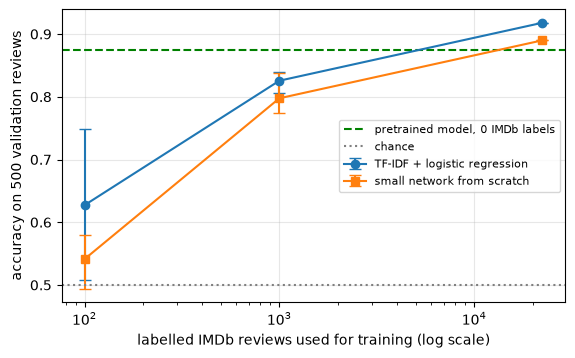

In [21]:
plt.figure(figsize=(6.5, 3.8))
for method, marker in [("TF-IDF + logistic regression", "o-"), ("small network from scratch", "s-")]:
    means = [np.mean(results[(method, n)]) for n in sizes]
    lo = [np.mean(results[(method, n)]) - min(results[(method, n)]) for n in sizes]
    hi = [max(results[(method, n)]) - np.mean(results[(method, n)]) for n in sizes]
    plt.errorbar(sizes, means, yerr=[lo, hi], fmt=marker, capsize=4, label=method)
plt.axhline(acc_pretrained, color="green", ls="--", label="pretrained model, 0 IMDb labels")
plt.axhline(0.5, color="grey", ls=":", label="chance")
plt.xscale("log"); plt.xlabel("labelled IMDb reviews used for training (log scale)")
plt.ylabel("accuracy on 500 validation reviews"); plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

The picture shows the real trade-off. The dashed green line is what you get **for free**: no labels, no training, 0.874. The other two methods have to climb towards it with labelled data, and they need several thousand labels to reach it.

So why didn't the pretrained model win outright? Because it was adapted to a *different* dataset: SST-2's short single sentences, not IMDb's long reviews, which we also cut to 256 tokens. With enough labels of exactly the right kind, even a simple method can beat a powerful model that was tuned for something slightly different. That points to the natural next step, which Module 8 takes: start from the pretrained model and adapt it to *your* data. You then get its head start and the benefit of your labels.

> **Common mistake:** assuming the biggest or most famous model will win. A pretrained model is only as good as its match to your task. Always compare it against a simple baseline on your own data. Here, a TF-IDF model that trains in seconds beat a Transformer with tens of millions of parameters once it had enough labels.

> **Key terms**
> - **TF-IDF (term frequency–inverse document frequency):** a way of turning a text into numbers that counts each word, giving less weight to words that appear in most documents.
> - **Training from scratch:** training a model starting from random weights, using only your own data.
> - **Baseline:** a simple reference method that a more complex one must beat to justify its cost.

**Check yourself.**

1. Your team has 300 labelled examples of customer emails and needs a sentiment classifier next week. Based on this section's results, which approach would you try first, and why?

<details>
<summary>Worked answer</summary>

The pretrained model, measured against a simple baseline. With a few hundred labels, the results here showed TF-IDF and a network trained from scratch to be weak and unstable (TF-IDF averaged 0.627 with 100 labels, and the from-scratch network managed 0.798 even with 1,000), while the pretrained model scored 0.874 with none. Use the 300 labels to *evaluate* the pretrained model (and, as Module 8 shows, possibly to adapt it). Emails are not film reviews, so measure before trusting it.

</details>

We've treated the pretrained model as a black box that comes with weights. Now let's open the box and look at what you actually download.

## 6. Weights, Architecture and Configuration

When you download a model from the Hub, you mainly get two kinds of file: a **configuration** that describes the architecture, and a **weights** file that holds the learned numbers. The code that turns them into a working network lives in the Transformers library on your computer. (A third group of files, for the tokeniser, comes alongside; Note 7.2 lists them all.)

### 6.1 The configuration

The configuration is a small JSON file, readable as plain text. It was downloaded with the model and is already in the local cache.

In [22]:
config_path = hf_hub_download(SST2, "config.json", revision=MODEL_REVISIONS.get(SST2))          # already in the local cache
print(open(config_path).read())

{
  "activation": "gelu",
  "architectures": [
    "DistilBertForSequenceClassification"
  ],
  "attention_dropout": 0.1,
  "dim": 768,
  "dropout": 0.1,
  "finetuning_task": "sst-2",
  "hidden_dim": 3072,
  "id2label": {
    "0": "NEGATIVE",
    "1": "POSITIVE"
  },
  "initializer_range": 0.02,
  "label2id": {
    "NEGATIVE": 0,
    "POSITIVE": 1
  },
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "output_past": true,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "vocab_size": 30522
}



Most of these lines describe the architecture in Module 6's terms:
- `dim: 768` is the width of every token's vector (called `d_model` in Module 6);
- `n_layers: 6` and `n_heads: 12` are the number of Transformer blocks and the number of attention heads in each;
- `hidden_dim: 3072` is the width inside each feed-forward network;
- `vocab_size: 30522` and `max_position_embeddings: 512` set the size of the word table and the longest input the model can take;
- `dropout` values are used only during training.

Two lines belong to the task, not the architecture: `id2label` maps output 0 to NEGATIVE and output 1 to POSITIVE, which is how the pipeline knew which word to print, and `finetuning_task` records that it was adapted on SST-2. This is the file we used in Section 1.3 to build the untrained twin.

### 6.2 Where the parameters are

Let's count the parameters in each part of the model.

In [23]:
groups = {}
for n, p in sst2_model.named_parameters():
    part = ("embeddings" if ".embeddings." in n else
            "transformer layers" if ".transformer." in n else "classification head")
    groups[part] = groups.get(part, 0) + p.numel()
total = sum(groups.values())
for part, k in groups.items():
    print(f"{part:<20} {k:>11,}  ({k / total:.1%})")
print(f"{'total':<20} {total:>11,}")

embeddings            23,835,648  (35.6%)
transformer layers    42,527,232  (63.5%)
classification head      592,130  (0.9%)
total                 66,955,010


The model has 66,955,010 parameters. More than a third of them, 35.6%, are in the embedding tables, before any Transformer layer is reached. The six Transformer layers hold 63.5%, and the sentiment head only 0.9%. We can check the embedding count by hand from the configuration:

In [24]:
cfg = sst2_model.config
print(f"word embeddings:     {cfg.vocab_size:,} words x {cfg.dim} numbers = {cfg.vocab_size * cfg.dim:,}")
print(f"position embeddings: {cfg.max_position_embeddings} positions x {cfg.dim} numbers = {cfg.max_position_embeddings * cfg.dim:,}")

word embeddings:     30,522 words x 768 numbers = 23,440,896
position embeddings: 512 positions x 768 numbers = 393,216


The word table alone is 30,522 rows of 768 numbers, which is 23,440,896 parameters, and the position table adds 393,216. Together with two small LayerNorm vectors, that makes the 23,835,648 above. This split matters in practice: a large vocabulary is expensive, and Note 7.6 will see it again when we shrink models.

### 6.3 From parameters to file size

Each parameter is stored as a 32-bit floating-point number, which takes 4 bytes. So the weights file should be about four times the parameter count:

In [25]:
weights_path = hf_hub_download(SST2, "model.safetensors", revision=MODEL_REVISIONS.get(SST2))
print(f"model.safetensors on disk: {os.path.getsize(weights_path) / 1e6:.1f} MB")
print(f"{total:,} parameters x 4 bytes each = {total * 4 / 1e6:.1f} MB")

model.safetensors on disk: 267.8 MB
66,955,010 parameters x 4 bytes each = 267.8 MB


It is: 66,955,010 parameters × 4 bytes is 267.8 MB, exactly the size of the file. The `.safetensors` format stores raw numbers with a short index and nothing else. Unlike Python's general-purpose `pickle` format, loading it cannot run hidden code, which makes it the safe choice for files downloaded from strangers. Note 7.6 builds on this rule, *parameters × bytes per parameter*, to estimate memory.

The weights themselves are stored as a **state dict**: a dictionary from each weight's name to its tensor, exactly as in your own PyTorch models.

In [26]:
sd = sst2_model.state_dict()
print(len(sd), "named tensors; the first and last four:")
for k in list(sd)[:4] + list(sd)[-4:]:
    print(f"  {k:<58} {tuple(sd[k].shape)}")

104 named tensors; the first and last four:
  distilbert.embeddings.word_embeddings.weight               (30522, 768)
  distilbert.embeddings.position_embeddings.weight           (512, 768)
  distilbert.embeddings.LayerNorm.weight                     (768,)
  distilbert.embeddings.LayerNorm.bias                       (768,)
  pre_classifier.weight                                      (768, 768)
  pre_classifier.bias                                        (768,)
  classifier.weight                                          (2, 768)
  classifier.bias                                            (2,)


There are 104 named tensors. The names spell out where each one lives (`distilbert.embeddings.word_embeddings.weight` has shape `(30522, 768)`, one row per vocabulary word), and the last four are the head: a `768 × 768` layer followed by a `2 × 768` layer that produces the two class scores.

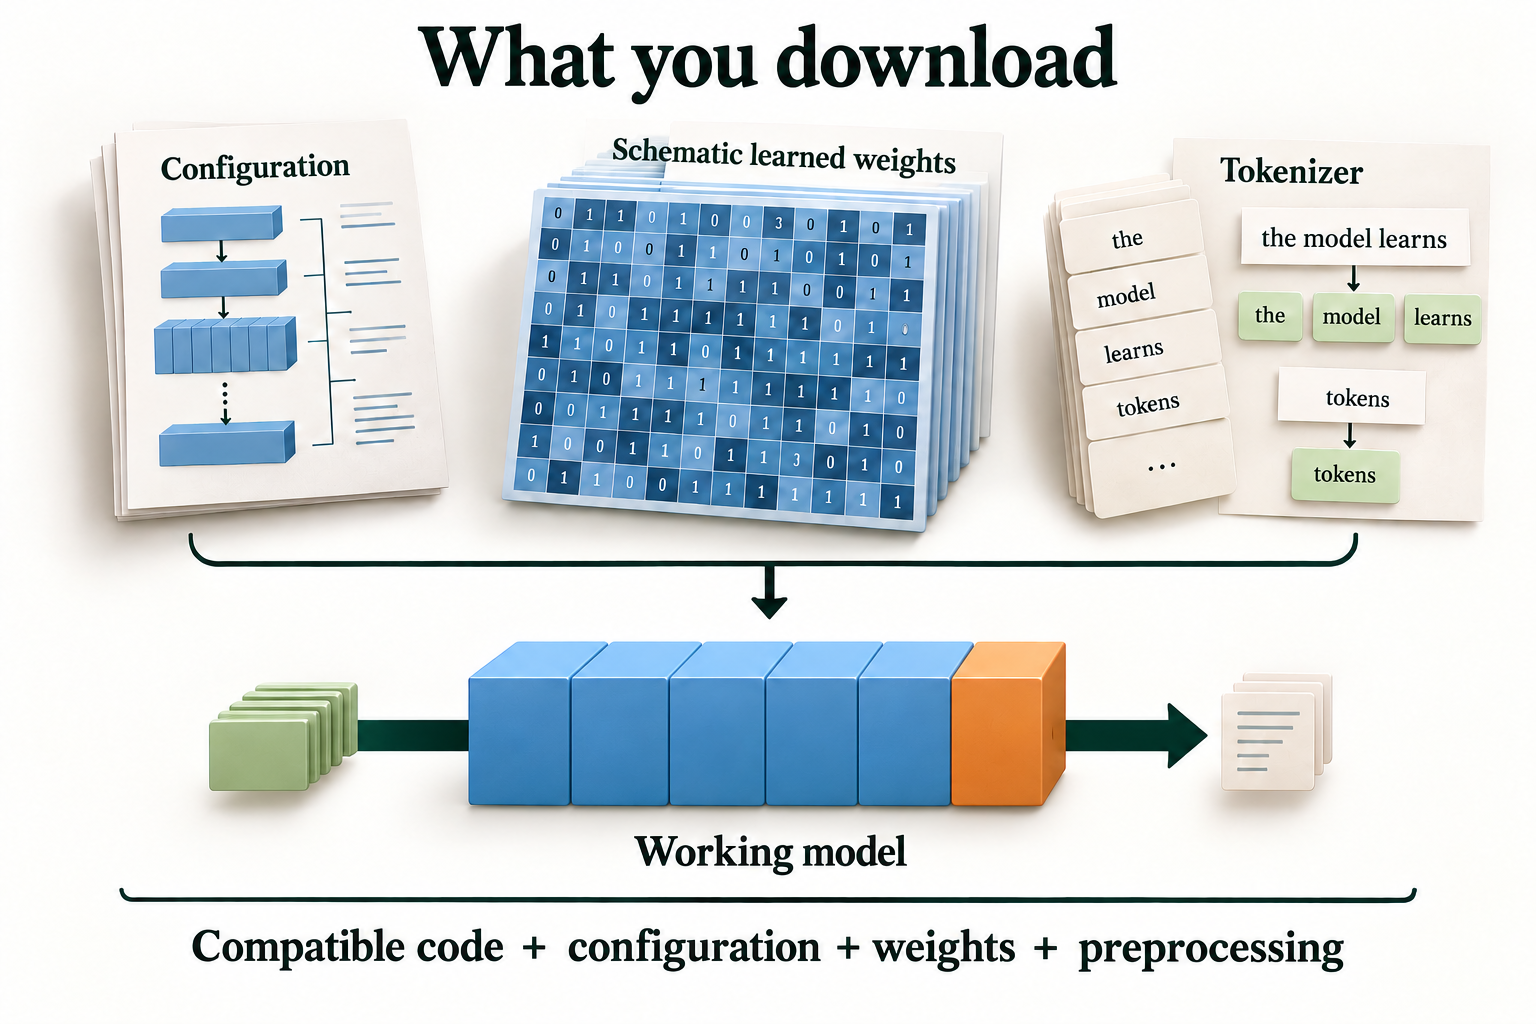

*Figure 7.1.4. Configuration describes the architecture, weights supply learned numbers, and the matching tokenizer defines the text interface. These schematic file objects are not a screenshot.*

> **Key terms**
> - **State dict:** a dictionary mapping each weight's name to its tensor; this is what gets saved and loaded.
> - **Safetensors:** a file format for storing weights as plain numbers, safe to load because it cannot contain executable code.
> - **Weight tying:** reusing one weight matrix in two places, such as the word-embedding table and the output layer that predicts words.

**Check yourself.**

1. A model has 110 million parameters stored as 32-bit numbers. Roughly how large is its weights file? How large would it be if each number were stored in 16 bits instead?

<details>
<summary>Worked answer</summary>

About 110 million × 4 bytes = 440 MB. At 16 bits (2 bytes) per number it would be about 220 MB. Note 7.6 explores what is lost and gained by storing numbers with fewer bits.

</details>

A weights file is a snapshot of a model at one moment. The last section looks at those snapshots, and at how models change over time.

## 7. Checkpoints and Model Versions

### 7.1 Checkpoints

A **checkpoint** is a saved set of weights (together with its configuration) from a particular moment in a model's training. In Note 5.3 you kept a copy of the weights from the best epoch; that copy was a checkpoint. On the Hub, each published model is a checkpoint, and models are often built from one another: the SST-2 model is a checkpoint made by fine-tuning the base checkpoint.

How much did that fine-tuning change? We can measure it directly. Below we load the base model's body and compare every tensor with the SST-2 body, using the *relative change*: the size of the difference divided by the size of the original.

In [27]:
base_body = AutoModel.from_pretrained(BASE, revision=MODEL_REVISIONS.get(BASE))                       # the base checkpoint, body only
sd0 = base_body.state_dict()
sd1 = {k: v.cpu() for k, v in sst2_model.distilbert.state_dict().items()}   # the SST-2 checkpoint's body
rel = {k: ((sd1[k] - sd0[k]).norm() / sd0[k].norm()).item() for k in sd0}  # relative change per tensor
print(len(rel), "tensors compared | identical:", sum(r == 0 for r in rel.values()))
by_part = {}
for k, r in rel.items():
    part = "embeddings" if k.startswith("embeddings") else "layer " + k.split(".")[2]
    by_part.setdefault(part, []).append(r)
for part, rs in by_part.items():
    print(f"{part:<11} average relative change {np.mean(rs):.2%}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 23624.56it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


100 tensors compared | identical: 0
embeddings  average relative change 1.85%
layer 0     average relative change 2.41%
layer 1     average relative change 2.16%
layer 2     average relative change 2.31%
layer 3     average relative change 2.18%
layer 4     average relative change 2.14%
layer 5     average relative change 2.33%


All 100 tensors in the body changed (none is identical), but only a little: on average by 1.85% in the embeddings and between 2.14% and 2.41% in the Transformer layers. Fine-tuning didn't rebuild the model. It nudged every weight slightly, and that was enough to turn a word-guesser into a sentiment classifier. Module 8 makes those nudges itself.

### 7.2 Versions

Models on the Hub are stored in **repositories** that track their history, like code on GitHub. Each change is a **commit** with its own ID, and a model's files can be updated after you first use them. When the library downloads a model, it stores the files in a cache folder named after the exact commit.

In [28]:
print("local snapshot folder:", os.path.basename(os.path.dirname(config_path)))
commits = HfApi().list_repo_commits(SST2)
print(len(commits), "commits in the repository; the latest three:")
for c in commits[:3]:
    print(f"  {c.commit_id[:12]}  {c.created_at:%Y-%m-%d}  {c.title}")

local snapshot folder: 714eb0fa89d2f80546fda750413ed43d93601a13


26 commits in the repository; the latest three:
  714eb0fa89d2  2023-12-19  Change loaded mode to correct on that this model card refers to (#26)
  4643665f84c6  2023-10-26  Adding ONNX file of this model (#23)
  3d65bad49c7b  2023-03-21  Addition of paper (#21)


The folder our files came from is named `714eb0fa89d2…`, the same ID as the latest of the repository's 26 commits. The three latest commit titles describe changes to the documentation and an extra file format, but a commit *could* just as easily replace the weights. If your application has to give the same answers next month, ask for an exact version with `revision=`:

In [29]:
pinned = AutoModelForSequenceClassification.from_pretrained(SST2, revision=commits[0].commit_id)   # exactly this version
same = all(torch.equal(a.cpu(), b) for a, b in zip(sst2_model.state_dict().values(), pinned.state_dict().values()))
print("pinned revision has identical weights to the model we used:", same)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 12060.60it/s]

pinned revision has identical weights to the model we used: True


Pinning a revision is the model equivalent of fixing a library version in `requirements.txt`. Note 7.6 returns to this when we look at reproducibility in deployed systems.

> **Key terms**
> - **Checkpoint:** a saved snapshot of a model's weights and configuration at a particular point in training.
> - **Repository (repo):** a Hub storage space for one model, with its files and their full history.
> - **Commit and revision:** a commit is one recorded change to a repository, identified by a long ID; a revision is the version you ask for, which can be a commit ID or a branch name such as `main`.

> **Common mistake:** loading a model by name only in a system that must stay reproducible. `from_pretrained(name)` gives you whatever the latest version is on the day you download it. Pin the commit with `revision=` and record it next to your results.

**Check yourself.**

1. A colleague reruns your evaluation a year from now and gets a different accuracy, with the same code and the same data. Name two things that could have changed, and how pinning would help with one of them.

<details>
<summary>Worked answer</summary>

The model could have changed (someone pushed new weights or a new tokeniser to the repository), or the software could have changed (a new library version that processes text or computes results slightly differently). Pinning the model with `revision=` and its commit ID removes the first risk; pinning library versions in `requirements.txt` handles the second.

</details>

## Putting It All Together

Let's reassemble the whole picture.

A **pretrained model** is a model whose weights someone else has already learned. It reaches us as a blueprint (the **configuration**) and a large file of numbers (the **weights**), and the code that assembles them comes from a library. We measured that trained weights matter with the architecture and tokeniser held fixed: the SST-2 model scored 0.874 on 500 IMDb validation reviews, and the same architecture with random weights scored 0.486, which is chance.

Those weights come from a two-stage **lifecycle**. **Pretraining** on large unlabelled text, here by guessing masked words, produces a **base model**. It learned grammar and common patterns well (it filled "she [MASK] to the cinema" with "went", and "so boring that I fell [MASK]" with "asleep"), but facts unreliably, and it built **contextual representations** in which "bank" by a river and "bank" with a loan pull apart layer by layer. **Downstream**, the same body is shared by many tasks, each with its task-specific output head; fine-tuning may update the body too. The mean relative tensor-norm changes in the body were around 2%; this is not a percentage change for every scalar weight.

| Approach | Labelled IMDb reviews | Accuracy on 500 validation reviews |
|---|---|---|
| Same architecture, random weights | 0 | 0.486 |
| Pretrained (SST-2) model, off the shelf | 0 | 0.874 |
| TF-IDF + logistic regression | 100 / 1,000 / 22,404 | 0.627 / 0.826 / 0.918 |
| Small network from scratch | 100 / 1,000 / 22,404 | 0.541 / 0.798 / 0.890 |

In this experiment, the pretrained checkpoint was strongest at the smaller label budgets: it gave, for free, what simpler methods needed thousands of labels to reach. It is not automatically the best: with all 22,404 labels, TF-IDF beat it (sign test p = 0.008), because the model had been tuned on different data. The lesson for the rest of Modules 7 and 8 is to treat a pretrained model as a strong starting point, always measured against a baseline, and adapted to your data when it doesn't fit.

Finally, models change. A **checkpoint** is one snapshot, and a Hub repository holds many **revisions**; pinning one makes your results reproducible.

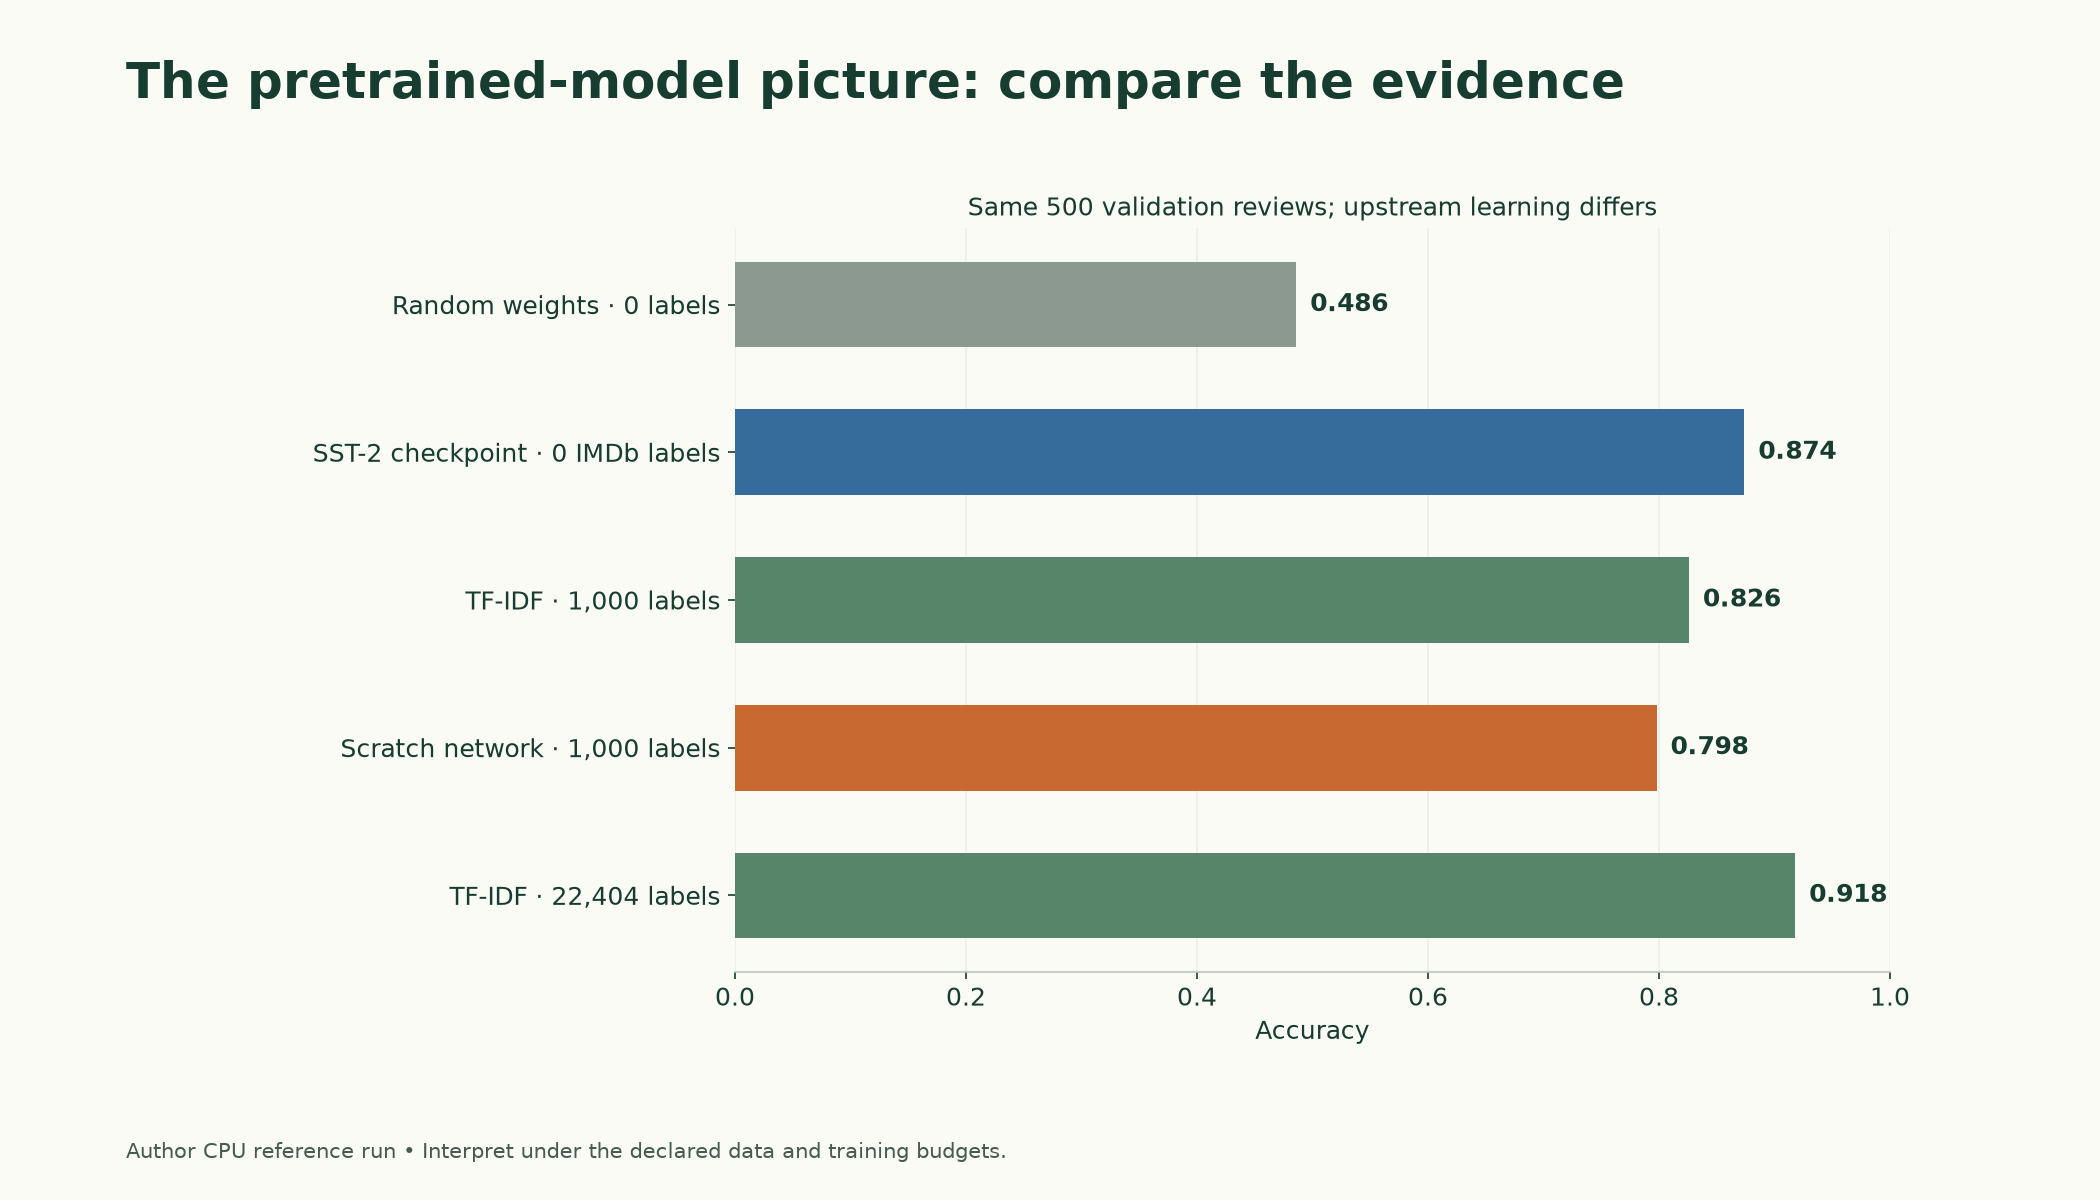

*Figure 7.1.5. Author CPU reference results on the same 500 validation reviews. Label budgets and prior training differ; these measurements do not establish a universal winner.*

## Summary

- A **pretrained model** is a model whose weights were learned by someone else and published. With the architecture and tokeniser fixed, trained weights matter: on 500 IMDb reviews the SST-2 model scored 0.874, and the same architecture with random weights scored 0.486.
- Models follow a **lifecycle**: pretraining on large unlabelled data produces a **base model**; fine-tuning on labelled data adapts it to a **downstream task**.
- DistilBERT was pretrained by **masked language modelling**. Probing with blanks showed strong grammar and cause-and-effect, but unreliable facts.
- Pretraining builds **contextual representations**: the gap between "bank" (money) and "bank" (river) was absent at the input and grew to 0.237 by the last layer.
- A **foundation model** shares one pretrained body across many tasks; a task-specific head provides the output interface; adapting the body is a separate choice. Hugging Face's LOAD REPORT shows which weights are reused (or skipped as UNEXPECTED) and which are new (MISSING).
- With few labels, the pretrained model beat TF-IDF and a network trained from scratch. With all 22,404 labels, TF-IDF beat it (0.918, sign test p = 0.008), because the model was tuned on different data. Always compare against a baseline.
- A model is a **configuration** (architecture and labels) plus **weights**. DistilBERT has 66,955,010 parameters, 35.6% of them in its embedding tables; at 4 bytes each that is the 267.8 MB file.
- A **checkpoint** is a saved snapshot; fine-tuning for SST-2 gave mean relative tensor-norm changes of around 2% across the body groups. Hub repositories keep **revisions**, and `revision=` pins one.

## Glossary

| Term | Meaning |
|---|---|
| Pretrained model | A model whose weights were learned by someone else on a large dataset and published for reuse. |
| Weights (parameters) | The learned numbers inside a model. |
| Architecture | The structure of a model: its layers, their sizes and how they connect. |
| Configuration | A file describing a model's architecture (and labels) so a library can rebuild it. |
| Pipeline | A Hugging Face helper that runs tokenising, the model and output decoding in one call. |
| Hugging Face Hub | A public website where models and datasets are shared. |
| IMDb | A dataset of movie reviews labelled positive or negative, used throughout Modules 7 and 8. |
| Fingerprint | A digest of sorted texts identifies membership under this implementation; a separate ordered text/label digest is needed to check paired prediction alignment. |
| Pretraining | The first, expensive training stage, on large and usually unlabelled data. |
| Masked language modelling | A pretraining task: predict hidden words from the words on both sides. |
| Base model | The model produced by pretraining, before adaptation to any task. |
| Downstream task | The task you actually want to solve with a pretrained model. |
| Fine-tuning | Further training of a pretrained model on labelled data for a downstream task. |
| SST-2 | A dataset of short film-review sentences labelled positive or negative. |
| Body (encoder) | The shared part of a model that builds representations. |
| Head | A small task-specific layer on top of the body. |
| Weight tying | Using one weight matrix in two places, such as the input word table and the word-prediction layer. |
| Probing | Testing what a model knows with inputs designed to need specific knowledge. |
| Contextual representation | A word vector that depends on the surrounding sentence. |
| Hidden states | The vectors produced after each layer of a Transformer. |
| Foundation model | A model pretrained on broad data, designed to be adapted to many tasks. |
| Transfer learning | Reusing what a model learned on one task to help with another. |
| LOAD REPORT | Hugging Face's table of skipped (UNEXPECTED) and newly created (MISSING) weights when loading. |
| TF-IDF | A word-count representation that down-weights words common to most documents. |
| Training from scratch | Training from random weights using only your own data. |
| Baseline | A simple reference method that a complex one must beat. |
| Sign test | A paired test that counts the examples where exactly one of two models is right. |
| State dict | A dictionary from each weight's name to its tensor. |
| Safetensors | A safe file format for weights that cannot contain executable code. |
| Checkpoint | A saved snapshot of a model's weights and configuration. |
| Repository | A Hub storage space for one model, with its files and history. |
| Commit / revision | A recorded change to a repository / the version you ask for when loading. |